# Clustering

In [33]:
import pandas as pd

In [34]:
users = pd.read_csv("../data_preprocessed/groups/users_wo_groups.csv")

In [35]:
users = users.drop(columns=["user_id", "group"])

users["married"] = users["married"].astype(int)
users["has_children"] = users["has_children"].astype(int)

users["gender"] = users["gender"].map({"F": 1, "M": 2, "O": 3})

users["avg_checked_bags"] = users["avg_checked_bags"].fillna(users["avg_checked_bags"].median())
users["avg_rooms"] = users["avg_rooms"].fillna(users["avg_rooms"].median())
users["avg_seats"] = users["avg_seats"].fillna(users["avg_seats"].median())
users["bags_per_seat"] = users["bags_per_seat"].fillna(users["bags_per_seat"].median())

users["cancellation_rate"] = users["cancellation_rate"].fillna(0)
users["flight_type_long"] = users["flight_type_long"].fillna(0)
users["flight_type_medium"] = users["flight_type_medium"].fillna(0)
users["flight_type_short"] = users["flight_type_short"].fillna(0)
users["total_flights"] = users["total_flights"].fillna(0)

users

,married,has_children,age,gender,avg_checked_bags,cancellation_rate,amount_trips,conversion_rate,avg_rooms,flight_type_long,flight_type_medium,flight_type_short,total_flights,booking_type_flight,booking_type_hotel,booking_type_none,booking_type_package,avg_seats,bags_per_seat
0,1,0,54,1,0.5,0.0,2,0.250,1.50,1.0,0.0,1.0,2.0,0,0,6,2,1.5,0.333333
1,1,1,53,1,0.0,0.0,2,0.250,1.50,1.0,0.0,0.0,1.0,0,1,6,1,1.0,0.000000
2,1,0,46,1,0.4,0.0,5,0.625,1.00,2.0,0.0,3.0,5.0,0,0,3,5,1.0,0.400000
3,0,1,54,1,1.0,0.0,5,0.625,1.25,1.0,1.0,1.0,3.0,1,2,3,2,2.0,0.500000
4,0,1,53,1,0.4,0.0,5,0.625,1.20,1.0,1.0,3.0,5.0,0,0,3,5,1.2,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4936,1,1,52,1,0.0,0.0,2,0.250,2.00,0.0,1.0,1.0,2.0,1,0,6,1,1.5,0.000000
4937,1,1,47,1,0.0,0.0,2,0.250,1.00,0.0,1.0,1.0,2.0,0,0,6,2,1.0,0.000000
4938,0,0,48,1,0.5,0.0,4,0.500,1.00,0.0,2.0,2.0,4.0,3,0,4,1,1.0,0.500000
4939,1,1,47,1,0.0,0.0,1,0.125,1.00,0.0,1.0,0.0,1.0,0,0,7,1,1.0,0.000000


In [36]:
users

,married,has_children,age,gender,avg_checked_bags,cancellation_rate,amount_trips,conversion_rate,avg_rooms,flight_type_long,flight_type_medium,flight_type_short,total_flights,booking_type_flight,booking_type_hotel,booking_type_none,booking_type_package,avg_seats,bags_per_seat
0,1,0,54,1,0.5,0.0,2,0.250,1.50,1.0,0.0,1.0,2.0,0,0,6,2,1.5,0.333333
1,1,1,53,1,0.0,0.0,2,0.250,1.50,1.0,0.0,0.0,1.0,0,1,6,1,1.0,0.000000
2,1,0,46,1,0.4,0.0,5,0.625,1.00,2.0,0.0,3.0,5.0,0,0,3,5,1.0,0.400000
3,0,1,54,1,1.0,0.0,5,0.625,1.25,1.0,1.0,1.0,3.0,1,2,3,2,2.0,0.500000
4,0,1,53,1,0.4,0.0,5,0.625,1.20,1.0,1.0,3.0,5.0,0,0,3,5,1.2,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4936,1,1,52,1,0.0,0.0,2,0.250,2.00,0.0,1.0,1.0,2.0,1,0,6,1,1.5,0.000000
4937,1,1,47,1,0.0,0.0,2,0.250,1.00,0.0,1.0,1.0,2.0,0,0,6,2,1.0,0.000000
4938,0,0,48,1,0.5,0.0,4,0.500,1.00,0.0,2.0,2.0,4.0,3,0,4,1,1.0,0.500000
4939,1,1,47,1,0.0,0.0,1,0.125,1.00,0.0,1.0,0.0,1.0,0,0,7,1,1.0,0.000000


In [37]:
users["gender"].value_counts()

gender
1    4360
2     572
3       9
Name: count, dtype: int64

# Scaling


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
users_scaled = pd.DataFrame(
    scaler.fit_transform(users),
    columns=users.columns,
    index=users.index,
)

users_scaled

,married,has_children,age,gender,avg_checked_bags,cancellation_rate,amount_trips,conversion_rate,avg_rooms,flight_type_long,flight_type_medium,flight_type_short,total_flights,booking_type_flight,booking_type_hotel,booking_type_none,booking_type_package,avg_seats,bags_per_seat
0,1.145478,-0.611890,0.874411,-0.362023,-0.069937,-0.25538,-0.541787,-0.536313,0.995657,0.341760,-0.960918,0.194437,-0.371115,-0.532861,-0.585128,0.452472,-0.148097,0.896545,-0.366717
1,1.145478,1.634282,0.783266,-0.362023,-1.290289,-0.25538,-0.541787,-0.536313,0.995657,0.341760,-0.960918,-0.833062,-1.050507,-0.532861,1.142977,0.452472,-0.879110,-0.494545,-1.322850
2,1.145478,-0.611890,0.145249,-0.362023,-0.314008,-0.25538,1.427539,1.436294,-0.548789,1.405131,-0.960918,2.249435,1.667061,-0.532861,-0.585128,-1.369586,2.044945,-0.494545,-0.175490
3,-0.872998,1.634282,0.874411,-0.362023,1.150414,-0.25538,1.427539,1.436294,0.223434,0.341760,0.002535,0.194437,0.308277,1.342400,2.871082,-1.369586,-0.148097,2.287636,0.111350
4,-0.872998,1.634282,0.783266,-0.362023,-0.314008,-0.25538,1.427539,1.436294,0.068990,0.341760,0.002535,2.249435,1.667061,-0.532861,-0.585128,-1.369586,2.044945,0.061891,-0.366717
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4936,1.145478,1.634282,0.692120,-0.362023,-1.290289,-0.25538,-0.541787,-0.536313,2.540103,-0.721612,0.002535,0.194437,-0.371115,1.342400,-0.585128,0.452472,-0.879110,0.896545,-1.322850
4937,1.145478,1.634282,0.236395,-0.362023,-1.290289,-0.25538,-0.541787,-0.536313,-0.548789,-0.721612,0.002535,0.194437,-0.371115,-0.532861,-0.585128,0.452472,-0.148097,-0.494545,-1.322850
4938,-0.872998,-0.611890,0.327540,-0.362023,-0.069937,-0.25538,0.771097,0.778758,-0.548789,-0.721612,0.965988,1.221936,0.987669,5.092921,-0.585128,-0.762233,-0.879110,-0.494545,0.111350
4939,1.145478,1.634282,0.236395,-0.362023,-1.290289,-0.25538,-1.198229,-1.193849,-0.548789,-0.721612,0.002535,-0.833062,-1.050507,-0.532861,-0.585128,1.059825,-0.879110,-0.494545,-1.322850


# KMeans elbow plot


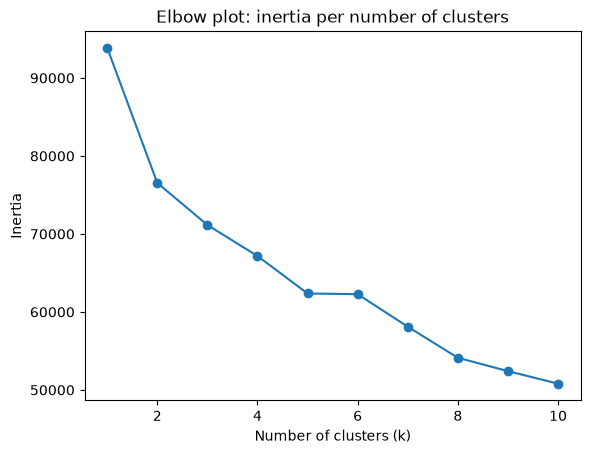

In [39]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(1, 11)
inertia = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    kmeans.fit(users_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(k_values, inertia, marker="o")
plt.title("Elbow plot: inertia per number of clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

# Silhouette score


2 0.1698
3 0.1107
4 0.1106
5 0.1215
6 0.0994
7 0.1085
8 0.1218
9 0.1179
10 0.1255


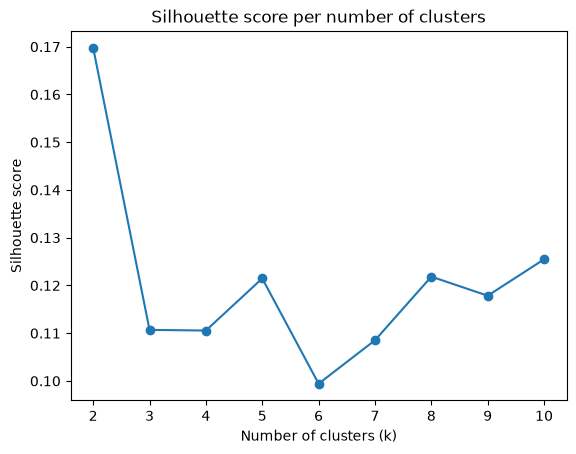

In [40]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in k_values:
    if k < 2:
        continue
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = kmeans.fit_predict(users_scaled)
    silhouette_scores.append(silhouette_score(users_scaled, labels))

for k, score in zip(k_values[1:], silhouette_scores):
    print(k, round(score, 4))

plt.plot(list(k_values)[1:], silhouette_scores, marker="o")
plt.title("Silhouette score per number of clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.show()

# KMeans with 2 clusters and PCA 3D


In [41]:
import plotly.express as px

# Load built-in sample dataset
df = px.data.iris()

fig = px.scatter_3d(
    df,
    x='sepal_length',
    y='sepal_width',
    z='petal_width',
    color='species',        # color points by species
    symbol='species',       # different marker shapes per species
    size='petal_length',    # marker size driven by a column
    opacity=0.8,
    title='Iris Dataset — 3D Scatter Plot'
)

fig.update_layout(width=700, height=600)
fig.write_html("test.html")

In [42]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import plotly.express as px

kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(users_scaled)

pca = PCA(n_components=3)
components = pca.fit_transform(users_scaled)

print("Explained variance of the 3 components:", round(pca.explained_variance_ratio_.sum(), 3))

pca_users = pd.DataFrame(components, columns=["PC1", "PC2", "PC3"], index=users_scaled.index)
pca_users["cluster"] = clusters.astype(str)

fig = px.scatter_3d(
    pca_users,
    x="PC1",
    y="PC2",
    z="PC3",
    color="cluster",
    opacity=0.7,
    width=1200,      # px
    height=800       # px
)

fig.write_html("test.html")

Explained variance of the 3 components: 0.485


# Users with clusters


In [43]:
users_clusters = users.copy()
users_clusters["cluster"] = clusters.astype(str)

users_clusters

,married,has_children,age,gender,avg_checked_bags,cancellation_rate,amount_trips,conversion_rate,avg_rooms,flight_type_long,flight_type_medium,flight_type_short,total_flights,booking_type_flight,booking_type_hotel,booking_type_none,booking_type_package,avg_seats,bags_per_seat,cluster
0,1,0,54,1,0.5,0.0,2,0.250,1.50,1.0,0.0,1.0,2.0,0,0,6,2,1.5,0.333333,0
1,1,1,53,1,0.0,0.0,2,0.250,1.50,1.0,0.0,0.0,1.0,0,1,6,1,1.0,0.000000,0
2,1,0,46,1,0.4,0.0,5,0.625,1.00,2.0,0.0,3.0,5.0,0,0,3,5,1.0,0.400000,1
3,0,1,54,1,1.0,0.0,5,0.625,1.25,1.0,1.0,1.0,3.0,1,2,3,2,2.0,0.500000,1
4,0,1,53,1,0.4,0.0,5,0.625,1.20,1.0,1.0,3.0,5.0,0,0,3,5,1.2,0.333333,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4936,1,1,52,1,0.0,0.0,2,0.250,2.00,0.0,1.0,1.0,2.0,1,0,6,1,1.5,0.000000,0
4937,1,1,47,1,0.0,0.0,2,0.250,1.00,0.0,1.0,1.0,2.0,0,0,6,2,1.0,0.000000,0
4938,0,0,48,1,0.5,0.0,4,0.500,1.00,0.0,2.0,2.0,4.0,3,0,4,1,1.0,0.500000,1
4939,1,1,47,1,0.0,0.0,1,0.125,1.00,0.0,1.0,0.0,1.0,0,0,7,1,1.0,0.000000,0


# Count plots per cluster and box plot per feature


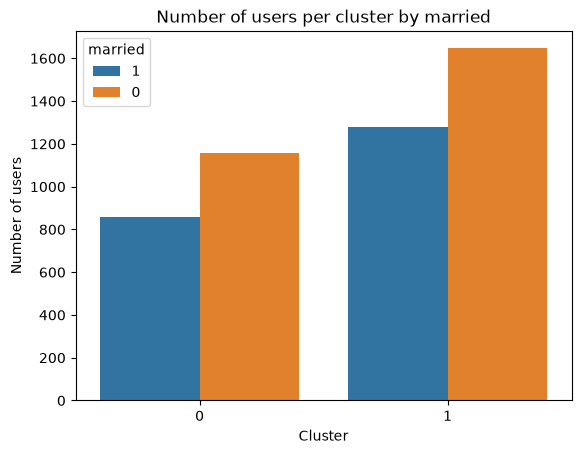

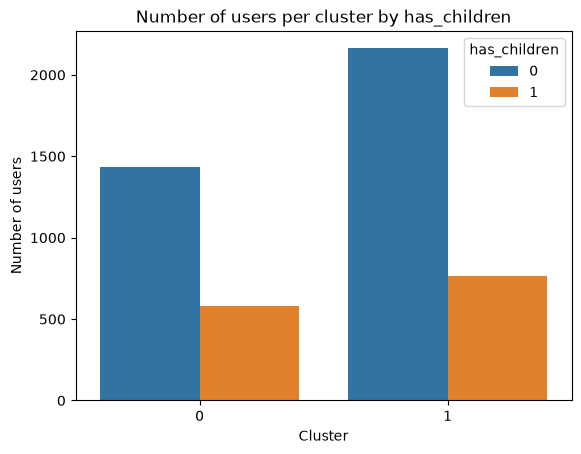

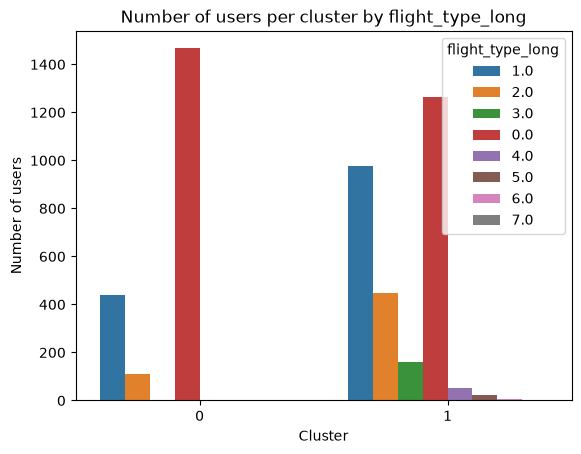

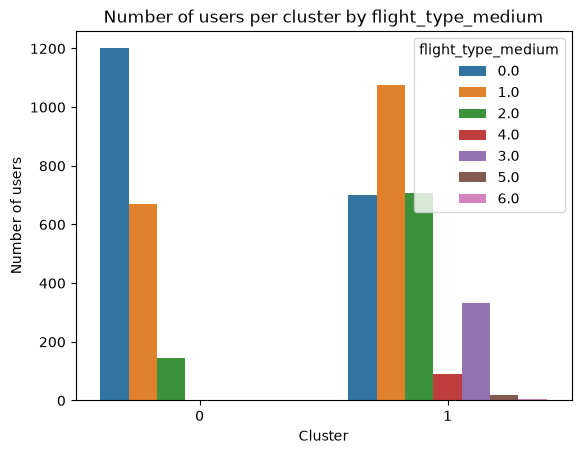

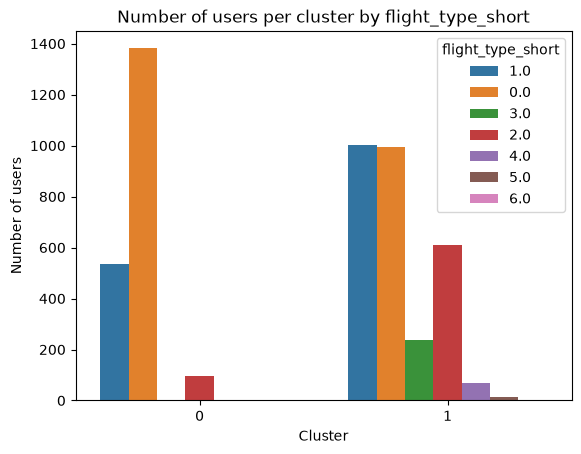

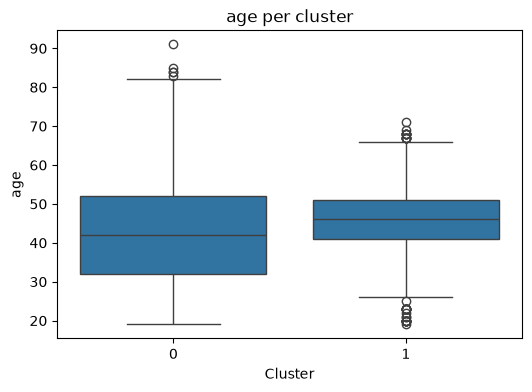

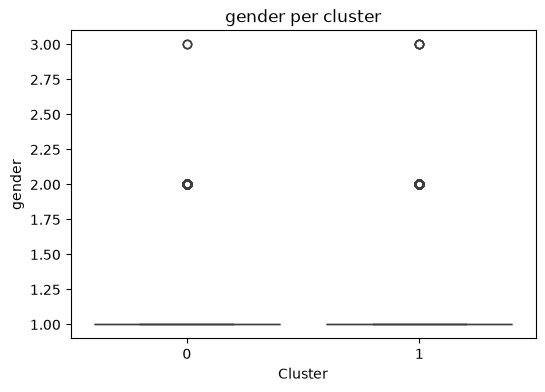

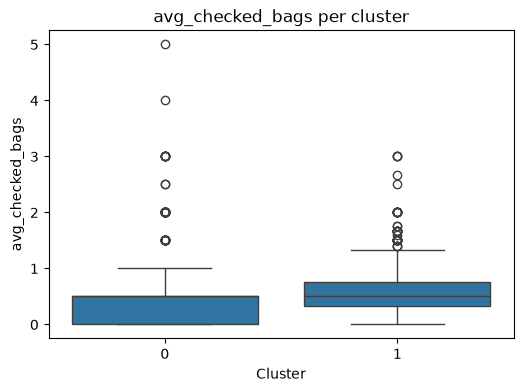

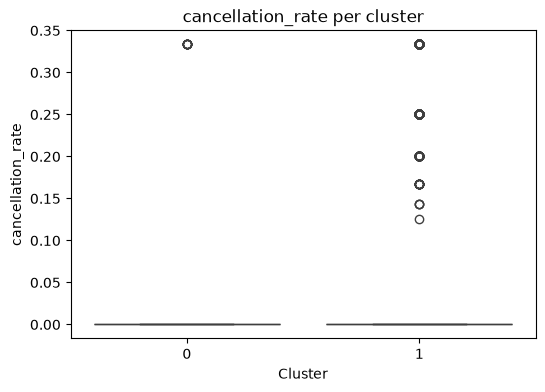

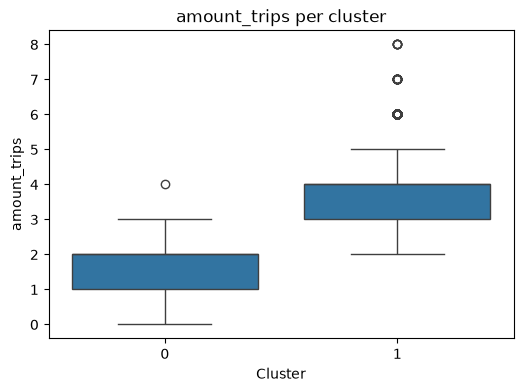

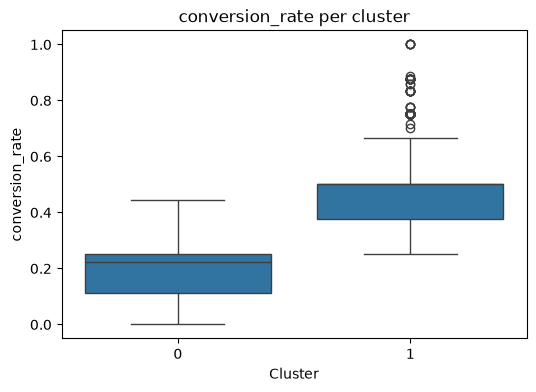

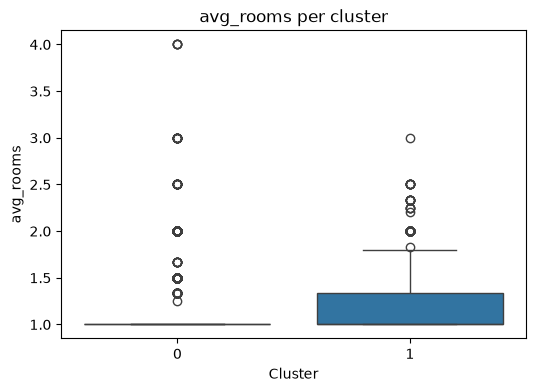

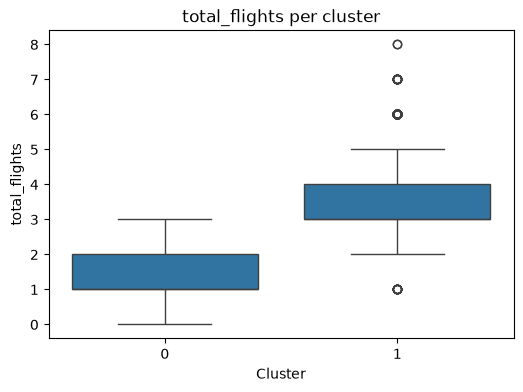

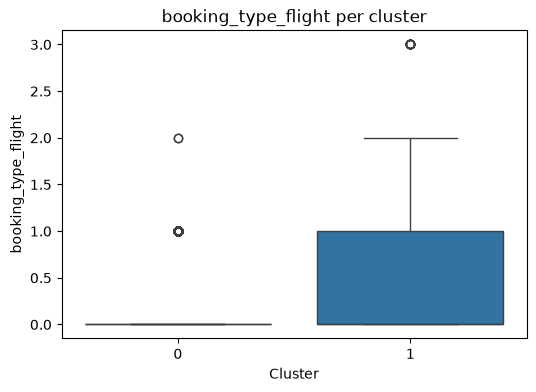

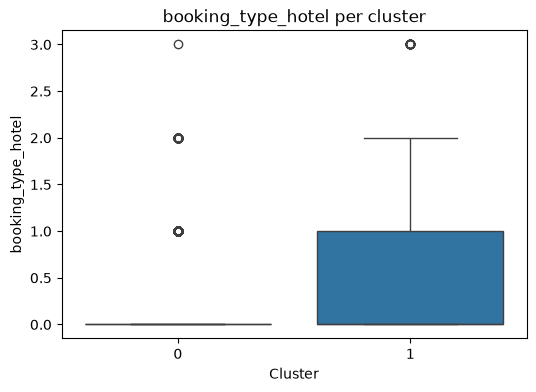

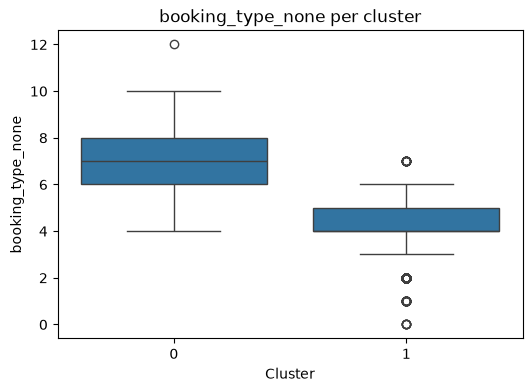

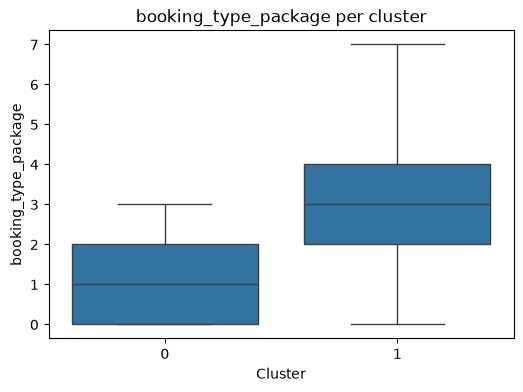

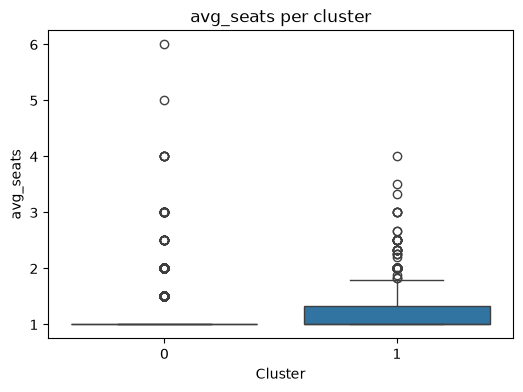

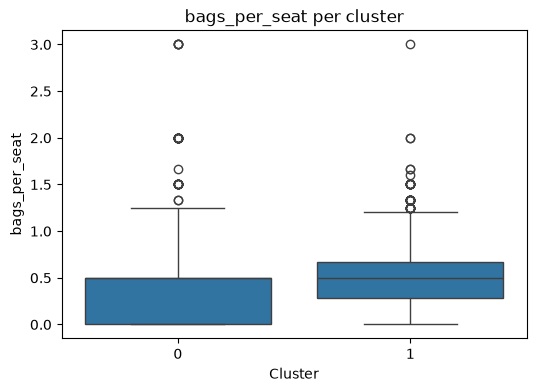

In [44]:
import seaborn as sns

count_features = [
    "married",
    "has_children",
    "flight_type_long",
    "flight_type_medium",
    "flight_type_short",
]

for feature in count_features:
    ax = sns.countplot(data=users_clusters, x="cluster", hue=users_clusters[feature].astype(str))
    ax.set_title(f"Number of users per cluster by {feature}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Number of users")
    ax.legend(title=feature)
    plt.show()

box_features = [
    column
    for column in users_clusters.columns
    if column not in count_features and column != "cluster"
]

for feature in box_features:
    plt.figure(figsize=(6, 4))
    ax = sns.boxplot(data=users_clusters, x="cluster", y=feature)
    ax.set_title(f"{feature} per cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(feature)
    plt.show()